# Initial set-up

In [1]:
# Install the extra packages we will need for this exercise, then restart the kernel (click on "Kernel"->"Restart Kernel...", or the refresh icon just above this notebook)
%pip install mplhep

Note: you may need to restart the kernel to use updated packages.


In [11]:
%pip install uproot

Note: you may need to restart the kernel to use updated packages.


# Opening files with uproot

In [6]:
import uproot

In [7]:
# Open the root file
tree = uproot.open("Zmumu.root")["physics"]
print(tree.keys())

['lep1_pt', 'lep1_eta', 'lep1_phi', 'lep1_E', 'lep1_m', 'lep2_pt', 'lep2_eta', 'lep2_phi', 'lep2_E', 'lep2_m', 'Z_pt', 'Z_eta', 'Z_phi', 'Z_E', 'Z_m']


In [14]:
print("Leading lepton pT:", tree["lep1_pt"].array())
print("Subleading lepton pT:", tree["lep2_pt"].array())

Leading lepton pT: [59.9, 33.9, 31.1, 39.3, 58.6, 45, 46, ..., 51.7, 46.9, 51.7, 39.5, 39.3, 35.1]
Subleading lepton pT: [36.1, 21.2, 29.8, 27.4, 32.2, 42.8, 22, ..., 48.3, 38.4, 30.4, 39, 29.6, 32.7]


## Aside: Opening a more complex example
The above example is quite simple, with two leptons in every event, and these are sorted into 1D arrays. To see a more complex example, try opening one of the files from the main analysis tutorial, and printing the keys and a branch (e.g. "Muon_Px")

In [15]:
complex_tree = uproot.open("http://theofil.web.cern.ch/theofil/cmsod/files/dy.root")["events"]

In [16]:
print(complex_tree.keys())

['NJet', 'Jet_Px', 'Jet_Py', 'Jet_Pz', 'Jet_E', 'Jet_btag', 'Jet_ID', 'NMuon', 'Muon_Px', 'Muon_Py', 'Muon_Pz', 'Muon_E', 'Muon_Charge', 'Muon_Iso', 'NElectron', 'Electron_Px', 'Electron_Py', 'Electron_Pz', 'Electron_E', 'Electron_Charge', 'Electron_Iso', 'NPhoton', 'Photon_Px', 'Photon_Py', 'Photon_Pz', 'Photon_E', 'Photon_Iso', 'MET_px', 'MET_py', 'MChadronicBottom_px', 'MChadronicBottom_py', 'MChadronicBottom_pz', 'MCleptonicBottom_px', 'MCleptonicBottom_py', 'MCleptonicBottom_pz', 'MChadronicWDecayQuark_px', 'MChadronicWDecayQuark_py', 'MChadronicWDecayQuark_pz', 'MChadronicWDecayQuarkBar_px', 'MChadronicWDecayQuarkBar_py', 'MChadronicWDecayQuarkBar_pz', 'MClepton_px', 'MClepton_py', 'MClepton_pz', 'MCleptonPDGid', 'MCneutrino_px', 'MCneutrino_py', 'MCneutrino_pz', 'NPrimaryVertices', 'triggerIsoMu24', 'EventWeight']


# Plotting
Going back to the first example file, plot the leading and subleading lepton pT using the [matplotlib hist](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html) function. Additionally add a legend and axis labels (remember to specify the units where appropriate!).

In [17]:
import matplotlib.pyplot as plt
import numpy as np
import mplhep

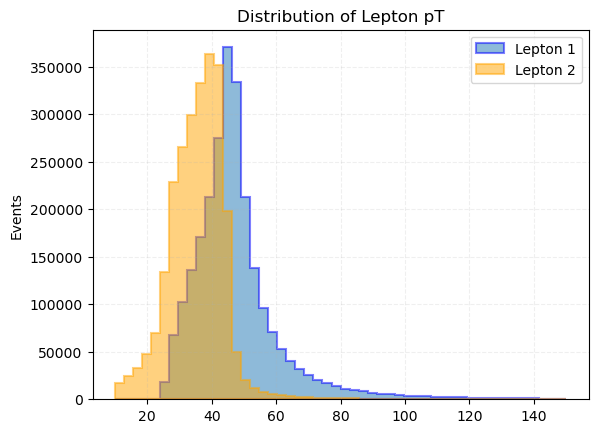

In [36]:
nbins = 50
start = 10
stop = 150
plt.hist(tree["lep1_pt"].array(), histtype='stepfilled', bins=nbins, range=(start, stop), alpha=0.5, label="Lepton 1", edgecolor='blue', linewidth=1.5) # alpha=0.5 makes the histogram semi-transparent so one can see two histograms on top of one another
# Complete the above example, and do the same for "lep2_pt" - note you'll need to change the color of the second histogram

plt.hist(tree["lep2_pt"].array(), histtype='stepfilled', bins=nbins, range=(start, stop), alpha=0.5, label="Lepton 2", color="orange", edgecolor='orange', linewidth=1.5)
plt.ylabel("Events")
plt.title("Distribution of Lepton pT")
plt.legend()
plt.grid(alpha=0.2, linestyle="--")
plt.show()


Now try plotting the leading lepton as a solid histogram, and the subleading lepton as an unfilled histogram (i.e. just an outline). It is possible to do this with matplotlib, but it is simpler to use the [mplhep.histplot](https://mplhep.readthedocs.io/en/latest/api.html#mplhep.histplot) function, which can do both of these. This requires another program to fill the events into the histogram bins, for which we can use [np.histogram](https://numpy.org/doc/stable/reference/generated/numpy.histogram.html)

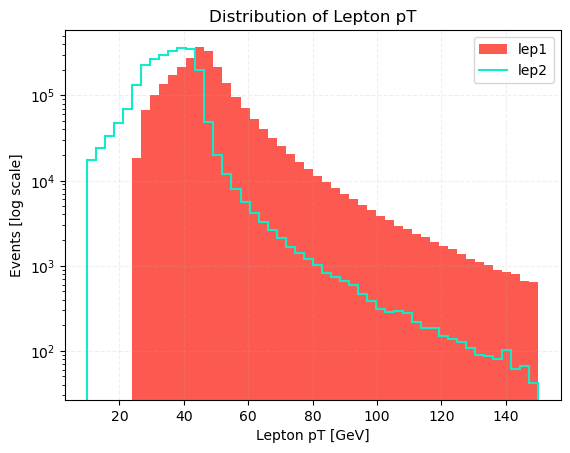

[10, 12.8, 15.6, 18.4, 21.2, 24, 26.8, ..., 133, 136, 139, 142, 144, 147, 150]


In [69]:
vals, bins = np.histogram(tree["lep1_pt"].array(), bins=nbins, range=(start, stop))
mplhep.histplot(vals, bins, color="xkcd:coral", label="lep1", histtype="fill")
# Complete the above example, and do the same for "lep2_pt"

vals, bins = np.histogram(tree["lep2_pt"].array(), bins=nbins, range=(start, stop))
mplhep.histplot(vals, bins, color="xkcd:aqua", label="lep2", histtype="step")

plt.yscale('log')

plt.ylabel("Events [log scale]")
plt.xlabel("Lepton pT [GeV]")
plt.title("Distribution of Lepton pT")
plt.legend()
plt.grid(alpha=0.2, linestyle="--")
plt.show()

print(f"{bins}")

Further things to try:
 - Change to a log y-axis
 - Change the colours using one of the different [matplotlib methods for specifying colours](https://matplotlib.org/stable/users/explain/colors/colors.html#colors-def) (a personal preference is the xkcd colours)
 - Add a label from your favourite experiment (see [here](https://mplhep.readthedocs.io/en/latest/api.html#mplhep.cms.label))

# Extension

Now try plotting the invariant mass of the two-lepton system, which is a useful way to reconstruct the Z boson mass experimentally. One could do this by converting the measured lepton transverse momentum ($p_{T}$), azimuthal angle ($\phi$), [pseudorapidity](https://en.wikipedia.org/wiki/Pseudorapidity) ($\eta$) and mass (m) to cartesian momentum and energy, summing the components and computing the mass of the resultant system, however in code it is normally easier, more maintainable and less error-prone to use external libraries. Complete the example below, and plot the resultant distribution.

In [72]:
pip install coffea

1820.97s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 12.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.0/36.0 MB 13.0 MB/s  0:00:02a 0:00:01m eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 10.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.4/22.4 MB 12.0 MB/s  0:00:01 eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 13.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 14.5 MB/s  0:00:00.3 MB/s eta 0:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 26/26 [coffea]m━ 25/26 [coffea]ipywidgets]
Note: you may need to restart the kernel to use updated packages.


In [4]:

from coffea.nanoevents.methods import vector
import awkward as ak

ak.behavior.update(vector.behavior)

In [8]:
# Create a Lorentz vector for the leading and subleading leptons
# Einträge der Lorentz Vektoren sind die 4er Komponenten (pt, eta, phi, mass)
# with_name="PtEtaPhiMLorentzVector" sorgt dafür, dass die Lorentz Vektor Methoden verfügbar sind, z.B. .mass

lead_lep = ak.Record({"pt": tree["lep1_pt"].array(),
                      "eta": tree["lep1_eta"].array(),
                      "phi": tree["lep1_phi"].array(),
                      "mass": tree["lep1_m"].array()},
                     with_name="PtEtaPhiMLorentzVector")
sublead_lep = ak.Record({"pt": tree["lep2_pt"].array(),
                         "eta": tree["lep2_eta"].array(),
                         "phi": tree["lep2_phi"].array(),
                         "mass": tree["lep2_m"].array()},
                        with_name="PtEtaPhiMLorentzVector")



# Berechnet aus dem 4er Vekrot dann die Masse über .mass
dilepton_mass = (lead_lep + sublead_lep).mass
lead_lep_mass = lead_lep.mass
sublead_lep_mass = sublead_lep.mass

print(f"dilepton mass: {dilepton_mass}")
print(f"lead lepton mass: {lead_lep_mass}")
print(f"sublead lepton mass: {sublead_lep_mass}")

dilepton mass: [96.4, 40.6, 89.4, 66.3, 90.1, 88.3, ..., 123, 89.4, 90.5, 91.7, 89.2, 100]
lead lepton mass: [0.093, 0.108, 0.105, 0.12, 0.107, ..., 0.103, 0.106, 0.106, 0.105, 0.106]
sublead lepton mass: [0.105, 0.103, 0.105, 0.105, 0.106, ..., 0.101, 0.105, 0.105, 0.106, 0.106]


Stats: 
Mean: 90.71 GeV
Std: 14.47 GeV


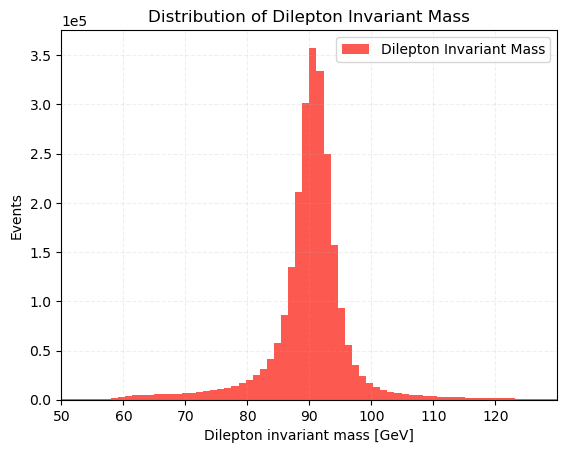

In [23]:
import matplotlib.pyplot as plt
import numpy as np
import mplhep


start1 = 50
stop1 = 130


#Statistik berechnen:
mean_val = np.mean(dilepton_mass)
std_val = np.std(dilepton_mass)


stats_text = f"Mean: {mean_val:.2f} GeV\nStd: {std_val:.2f} GeV"


#dilepton mass Histogramm
vals1, bins1 = np.histogram(dilepton_mass, bins=70, range=(start1, stop1))
mplhep.histplot(vals1, bins1, color="xkcd:coral", label="Dilepton Invariant Mass", histtype="fill")





# --> für Invariant mass, leading lepton mass, and subleading lepton mass, we can use the following code to plot them on the same histogram
# However: Muon mass = 0.1, so starting point must be way lower

# leading lepton mass
#vals2, bins2 = np.histogram(lead_lep_mass, bins=70, range=(start1, stop1))
#mplhep.histplot(vals2, bins2, color="xkcd:aqua", label="leading lepton mass", histtype="step")

# subleading lepton mass
#vals3, bins3 = np.histogram(sublead_lep_mass, bins=70, range=(start1, stop1))
#mplhep.histplot(vals3, bins3, color="xkcd:green", label="subleading lepton mass", histtype="step")  



print(f"Stats: \n{stats_text}")

plt.legend()
plt.ylabel("Events")
plt.xlabel("Dilepton invariant mass [GeV]")
plt.xticks(np.arange(start1, stop1, 10)) #Setzt die x-Achse in 10er Schritten
plt.xlim(start1, stop1) #x-Achse von 50 bis 130 GeV
plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0)) #Macht die y-Achse in wissenschaftlicher Notation

plt.title("Distribution of Dilepton Invariant Mass")
plt.grid(alpha=0.2, linestyle="--")
plt.show()